# Facial Expression Recognition — Recorded Results

This notebook reviews the finished V2 experiment using published prediction evidence. It requires no dataset images, pretrained-weight downloads, or training run. The reported score is a saved validation result; hidden-test quality is unknown.


In [1]:
from pathlib import Path
import json
import sys
import pandas as pd

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'MODEL_CARD.md').is_file())
sys.path.insert(0, str(ROOT / 'tools'))
from verify_public_evidence import verify
verify()


{'status': 'passed',
 'validation_rows': 5741,
 'accuracy': 0.6786274168263369,
 'macro_f1': 0.6439789079895994,
 'boundary': 'Saved prediction evidence only; training and hidden-test inference were not rerun.'}

## The fixed comparison
Candidates were selected by accuracy first and Macro F1 as a tie-breaker on one duplicate-safe holdout.

In [2]:
selection = json.loads((ROOT / 'outputs/selected_candidate.json').read_text())
pd.DataFrame(selection['ranking'])[['candidate_id', 'tta', 'validation_accuracy', 'validation_macro_f1']].head(10)


,candidate_id,tta,validation_accuracy,validation_macro_f1
0,ensemble_r01_resnet18_ce__r02_resnet18_smoothi...,True,0.678627,0.643979
1,ensemble_r01_resnet18_ce__r02_resnet18_smoothi...,True,0.677931,0.643440
2,ensemble_r01_resnet18_ce__r03_resnet18_augment...,True,0.677234,0.642012
3,ensemble_r01_resnet18_ce__r03_resnet18_augment...,True,0.676189,0.642152
4,ensemble_r02_resnet18_smoothing__r03_resnet18_...,True,0.675840,0.639863
5,ensemble_r01_resnet18_ce__r02_resnet18_smoothi...,False,0.672705,0.645699
6,ensemble_r02_resnet18_smoothing__r03_resnet18_...,False,0.672183,0.641092
7,ensemble_r01_resnet18_ce__r02_resnet18_smoothi...,False,0.671486,0.641213
8,ensemble_r03_resnet18_augment__r04_resnet18_gr...,True,0.671312,0.637025
9,ensemble_r01_resnet18_ce__r03_resnet18_augment...,False,0.671137,0.639155


In [3]:
audit = json.loads((ROOT / 'outputs/eda/audit_summary.json').read_text())
pd.Series({
    'labeled images': audit['dataset']['train_rows'],
    'validation images': audit['split']['validation_rows'],
    'exact hash overlap across development split': audit['split']['exact_hash_overlap'],
    'conflicting-label duplicate groups': audit['duplicates']['conflicting_training_label_groups'],
    'organizer train/test crossing groups': audit['duplicates']['groups_crossing_supplied_train_test'],
    'split hash': audit['split_hash'],
}, name='recorded audit')


labeled images                                                                             28709
validation images                                                                           5741
exact hash overlap across development split                                                    0
conflicting-label duplicate groups                                                            39
organizer train/test crossing groups                                                         531
split hash                                     43616ca5590b0eadc3b973ba002062dc49d10f5e2a8369...
Name: recorded audit, dtype: object

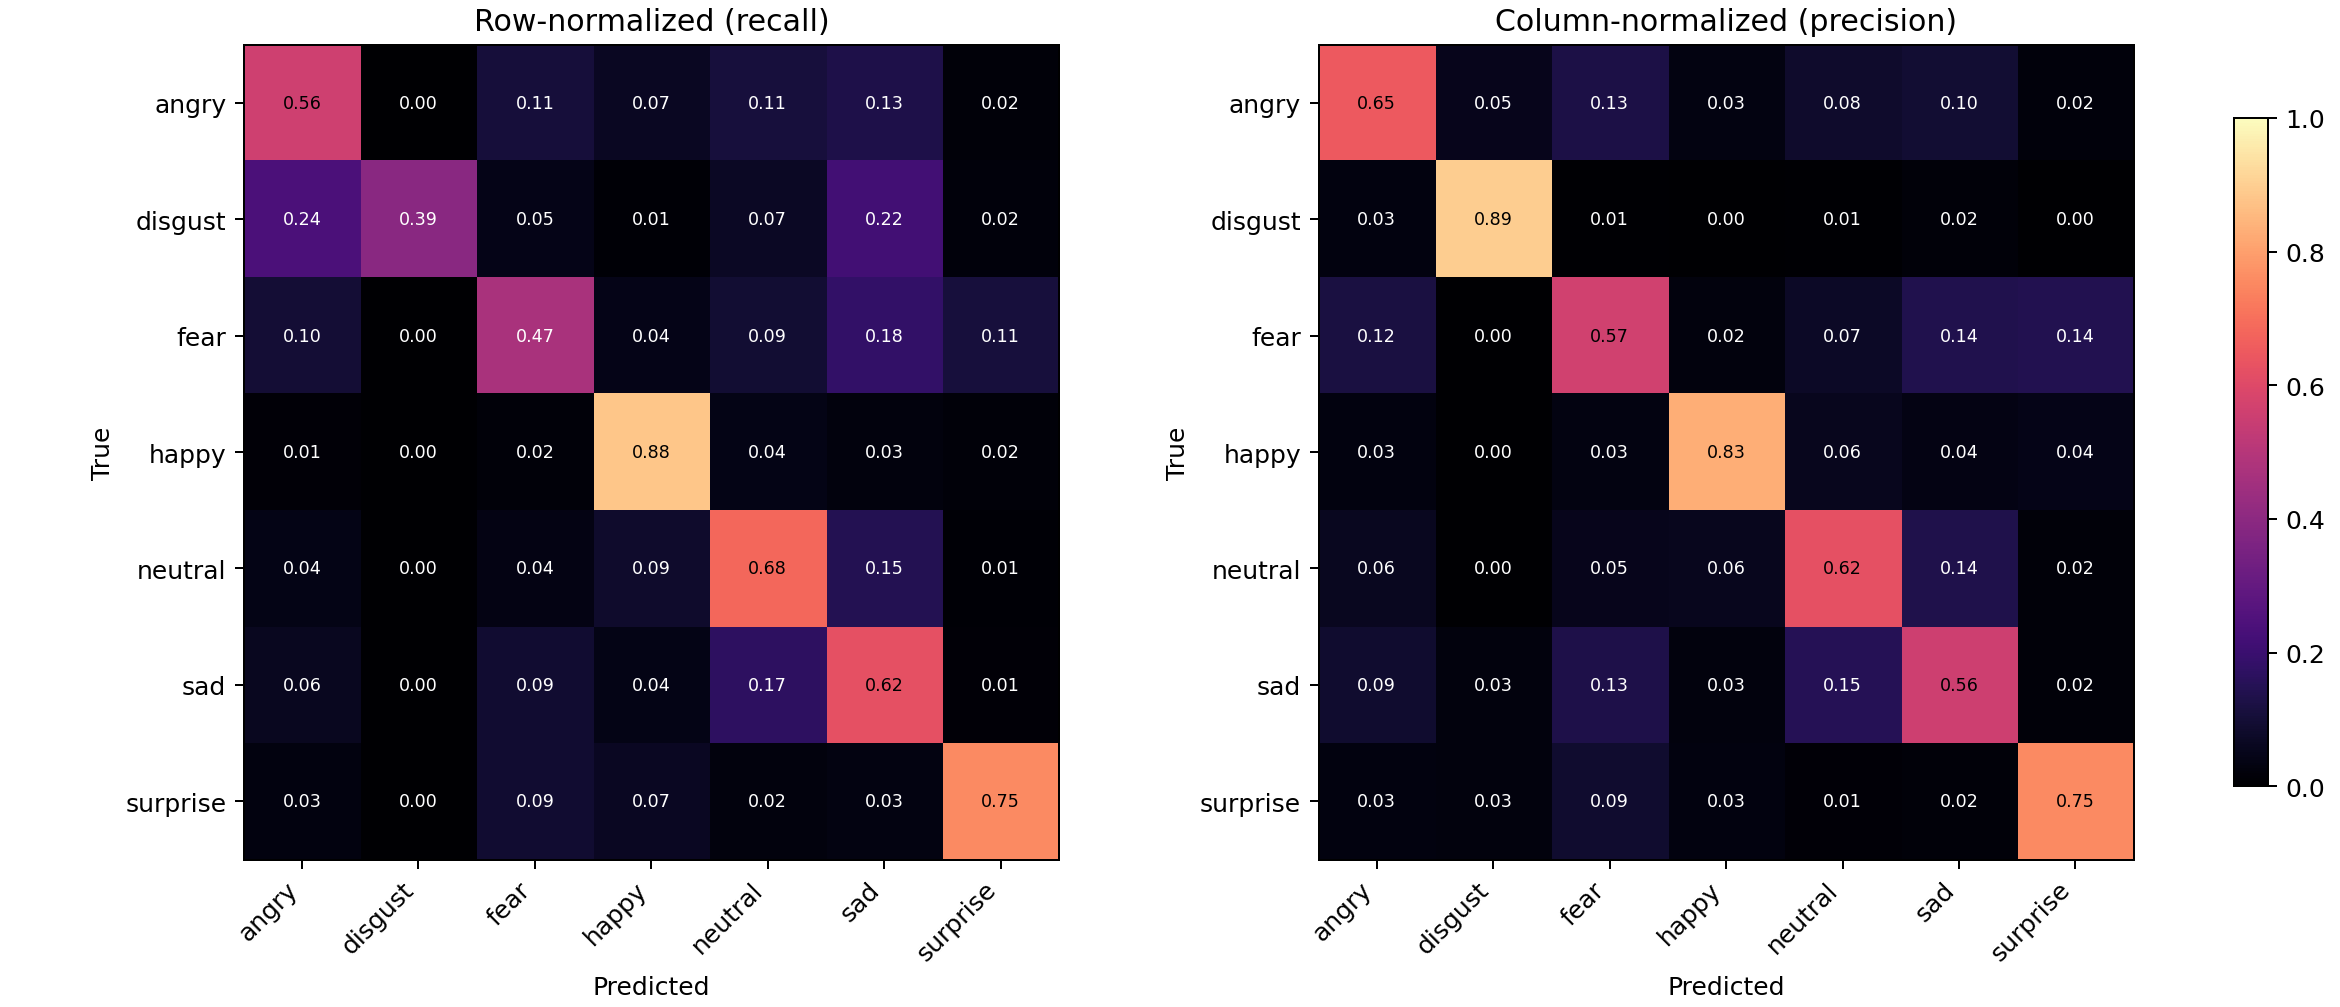

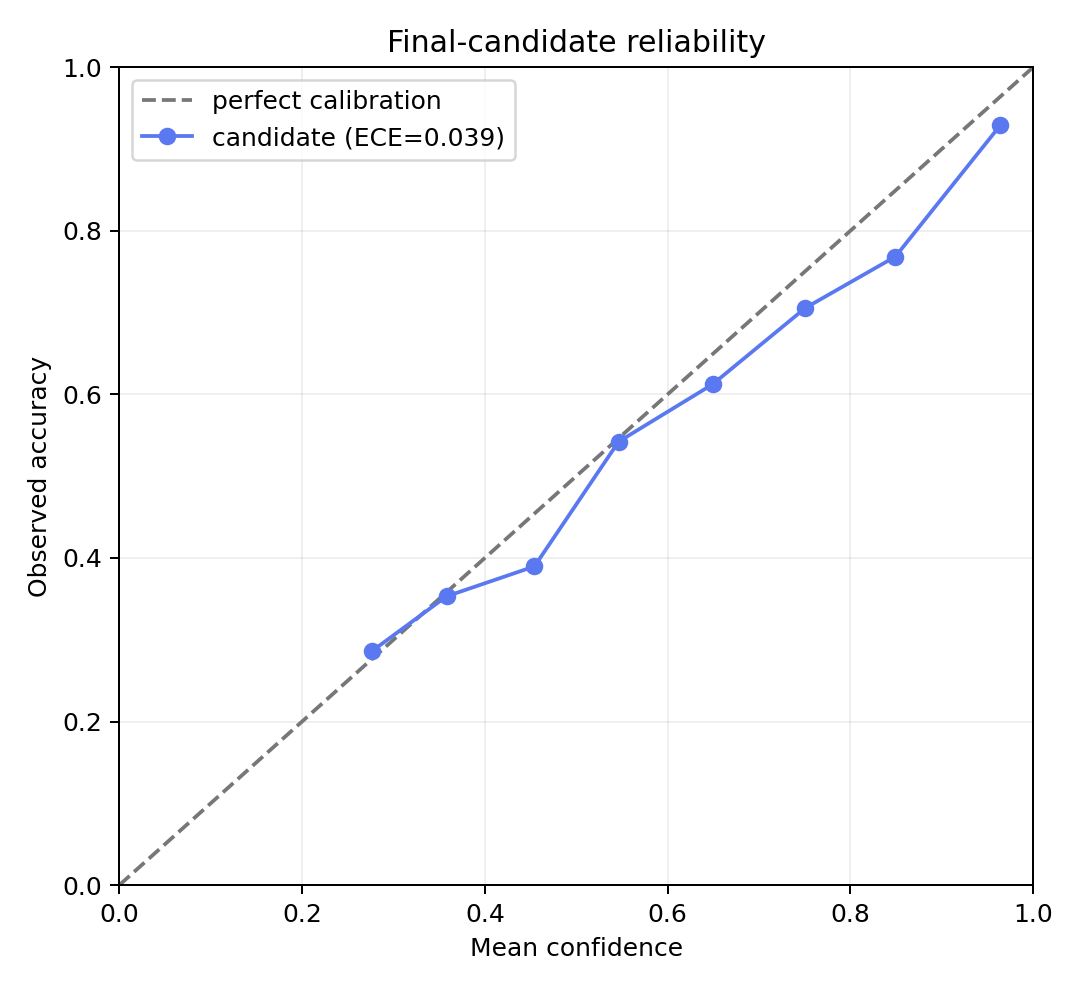

In [4]:
from IPython.display import Image, display
display(Image(filename=str(ROOT / 'outputs/final_analysis/confusion_matrices.png')))
display(Image(filename=str(ROOT / 'outputs/final_analysis/reliability_diagram.png')))


## Reproduction boundary

The source and four frozen experiment configurations are in this repository. To retrain, obtain the organizer dataset through its own access rules and follow the README. Model checkpoints and original face images are not distributed here. Rebuilding training and inference requires those external files.

One locked holdout does not characterize every deployment setting. Expression classification is an educational benchmark, not evidence of a person's true emotions. See the model card for class-level results and limitations.
